# Tercera Práctica Calificada - Computación Gráfica
## Nombre : MONTALVO ESPINOZA JOSÉ MANUEL - 20182722A

In [2]:
import os
import glob
import random
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, applications

# 1. DESCARGAR O LOCALIZAR CELEBA-HQ EN /content/
DATASET_DIR = "/content/celeba_hq_data"
MODEL_SAVE_PATH = "/content/srgan_tv_peru_gen.keras"

if not os.path.exists(DATASET_DIR) or len(glob.glob(f"{DATASET_DIR}/**/*.jpg", recursive=True)) == 0:
    print("Descargando CelebA-HQ con kagglehub...")
    import kagglehub
    path = kagglehub.dataset_download("badasstechie/celebahq-resized-256x256")
    DATASET_DIR = path
    print("Dataset descargado en:", DATASET_DIR)

all_images = glob.glob(os.path.join(DATASET_DIR, "**", "*.jpg"), recursive=True) + \
             glob.glob(os.path.join(DATASET_DIR, "**", "*.png"), recursive=True)

if len(all_images) == 0:
    raise FileNotFoundError("No se encontraron imágenes en CelebA-HQ.")

random.shuffle(all_images)
image_paths = all_images[:3000]
print(f"Total de imágenes HD de CelebA-HQ seleccionadas: {len(image_paths)}")

# 2. HIPERPARÁMETROS (Usa SCALE = 2 si tu video es 480p; usa 4 si es 240p/360p)
SCALE = 4
HR_SIZE = 128
LR_SIZE = HR_SIZE // SCALE
BATCH_SIZE = 16
EPOCHS_PRETRAIN = 10   # Fase 1: Estructura base (MAE)
EPOCHS_GAN = 30        # Fase 2: Reconstrucción perceptual + adversarial

# 3. PIPELINE DE DEGRADACIÓN TV ANTIGUA
def degrade_and_crop(img_path):
    path = img_path.numpy().decode('utf-8')
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    if h < HR_SIZE or w < HR_SIZE:
        img = cv2.resize(img, (max(w, HR_SIZE), max(h, HR_SIZE)))
        h, w, _ = img.shape

    top = np.random.randint(0, h - HR_SIZE + 1)
    left = np.random.randint(0, w - HR_SIZE + 1)
    hr_crop = img[top:top+HR_SIZE, left:left+HR_SIZE]

    blurred = cv2.GaussianBlur(hr_crop, (5, 5), 1.1)
    lr_crop = cv2.resize(blurred, (LR_SIZE, LR_SIZE), interpolation=cv2.INTER_AREA)
    quality = np.random.randint(30, 65)
    _, encimg = cv2.imencode('.jpg', lr_crop, [int(cv2.IMWRITE_JPEG_QUALITY), quality])
    lr_crop = cv2.imdecode(encimg, 1)

    lr_norm = (lr_crop / 255.0).astype(np.float32)
    hr_norm = ((hr_crop / 127.5) - 1.0).astype(np.float32)
    return lr_norm, hr_norm

def tf_parse(img_path):
    lr, hr = tf.py_function(degrade_and_crop, [img_path], [tf.float32, tf.float32])
    lr.set_shape([LR_SIZE, LR_SIZE, 3])
    hr.set_shape([HR_SIZE, HR_SIZE, 3])
    return lr, hr

dataset = tf.data.Dataset.from_tensor_slices(image_paths)
dataset = dataset.shuffle(2000).map(tf_parse, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 4. CAPA PERSONALIZADA PIXELSHUFFLE
@tf.keras.utils.register_keras_serializable()
class PixelShuffle(layers.Layer):
    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale

    def call(self, inputs):
        return tf.nn.depth_to_space(inputs, self.scale)

    def get_config(self):
        config = super().get_config()
        config.update({"scale": self.scale})
        return config

# 5. GENERADOR Y DISCRIMINADOR
def res_block(x):
    skip = x
    x = layers.Conv2D(64, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.PReLU(shared_axes=[1, 2])(x)
    x = layers.Conv2D(64, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    return layers.Add()([skip, x])

def build_generator(scale=2, num_res_blocks=8):
    inputs = layers.Input(shape=(None, None, 3))
    x = layers.Conv2D(64, 9, padding='same')(inputs)
    x = layers.PReLU(shared_axes=[1, 2])(x)
    skip = x

    for _ in range(num_res_blocks):
        x = res_block(x)

    x = layers.Conv2D(64, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Add()([skip, x])

    num_upsamples = 1 if scale == 2 else 2
    for _ in range(num_upsamples):
        x = layers.Conv2D(256, 3, padding='same')(x)
        x = PixelShuffle(scale=2)(x)
        x = layers.PReLU(shared_axes=[1, 2])(x)

    outputs = layers.Conv2D(3, 9, padding='same', activation='tanh')(x)
    return models.Model(inputs, outputs, name="SRGAN_Generator")

def build_discriminator():
    inputs = layers.Input(shape=(HR_SIZE, HR_SIZE, 3))
    x = layers.Conv2D(64, 3, padding='same')(inputs)
    x = layers.LeakyReLU(0.2)(x)

    for filters, strides in [(64, 2), (128, 1), (128, 2), (256, 1), (256, 2), (512, 1), (512, 2)]:
        x = layers.Conv2D(filters, 3, strides=strides, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(0.2)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return models.Model(inputs, outputs, name="SRGAN_Discriminator")

# 6. EXTRACTOR PERCEPTUAL VGG19 Y ENTRENAMIENTO EN 2 FASES
vgg_base = applications.VGG19(weights="imagenet", include_top=False, input_shape=(HR_SIZE, HR_SIZE, 3))
vgg_base.trainable = False
vgg = models.Model(vgg_base.input, vgg_base.get_layer("block5_conv4").output)

gen = build_generator(scale=SCALE, num_res_blocks=8)
disc = build_discriminator()

print("--- FASE 1: Pre-entrenamiento del Generador ---")
gen.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='mae')
gen.fit(dataset, epochs=EPOCHS_PRETRAIN)
gen.save(MODEL_SAVE_PATH)

print("--- FASE 2: Entrenamiento Adversarial SRGAN ---")
bce = tf.keras.losses.BinaryCrossentropy()
mse = tf.keras.losses.MeanSquaredError()
g_opt = tf.keras.optimizers.Adam(1e-4)
d_opt = tf.keras.optimizers.Adam(1e-4)

@tf.function
def train_step(lr_imgs, hr_imgs):
    with tf.GradientTape() as d_tape, tf.GradientTape() as g_tape:
        sr_imgs = gen(lr_imgs, training=True)

        real_logits = disc(hr_imgs, training=True)
        fake_logits = disc(sr_imgs, training=True)

        d_loss = 0.5 * (bce(tf.ones_like(real_logits) * 0.9, real_logits) + bce(tf.zeros_like(fake_logits), fake_logits))

        hr_vgg = vgg(applications.vgg19.preprocess_input((hr_imgs + 1.0) * 127.5))
        sr_vgg = vgg(applications.vgg19.preprocess_input((sr_imgs + 1.0) * 127.5))

        perceptual_loss = mse(hr_vgg, sr_vgg) * 0.02
        adversarial_loss = bce(tf.ones_like(fake_logits), fake_logits) * 3e-3
        pixel_loss = tf.reduce_mean(tf.abs(hr_imgs - sr_imgs)) * 1e-2

        g_loss = perceptual_loss + adversarial_loss + pixel_loss

    d_grads = d_tape.gradient(d_loss, disc.trainable_variables)
    g_grads = g_tape.gradient(g_loss, gen.trainable_variables)
    d_opt.apply_gradients(zip(d_grads, disc.trainable_variables))
    g_opt.apply_gradients(zip(g_grads, gen.trainable_variables))
    return g_loss, d_loss

for epoch in range(EPOCHS_GAN):
    for lr_b, hr_b in dataset:
        g_loss, d_loss = train_step(lr_b, hr_b)
    print(f"Época {epoch+1}/{EPOCHS_GAN} | G_loss: {g_loss:.4f} | D_loss: {d_loss:.4f}")

gen.save(MODEL_SAVE_PATH)
print(f"¡Entrenamiento terminado! Modelo guardado en: {MODEL_SAVE_PATH}")

Descargando CelebA-HQ con kagglehub...


100%|██████████| 283M/283M [00:01<00:00, 164MB/s]

Extracting files...


Dataset descargado en: /root/.cache/kagglehub/datasets/badasstechie/celebahq-resized-256x256/versions/1
Total de imágenes HD de CelebA-HQ seleccionadas: 3000
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- FASE 1: Pre-entrenamiento del Generador ---
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 73s 201ms/step - loss: 0.1518
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 111ms/step - loss: 0.1120
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 39s 101ms/step - loss: 0.1036
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 104ms/step - loss: 0.0991
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 104ms/step - loss: 0.0938
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 104ms/step - loss: 0.0889
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 103ms/step - loss: 0.0858
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - loss: 0.0843
Epoch 9/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 21s 104ms/step - loss: 0.0836
Epoch 10/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 101ms/step - loss: 0.0830
--- FASE 2: Entrenamiento Adversarial SRGA

## PROCESAMIENTO DEL VIDEO -  CÁLCULO DE MÉTRICAS

In [3]:
import os
import subprocess
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# 1. RUTAS LOCALES EN COLAB
MODEL_PATH = "/content/srgan_tv_peru_gen.keras"
INPUT_VIDEO = "/content/video_original.mp4"
TEMP_VIDEO = "/content/temp_sin_audio.mp4"
FINAL_OUTPUT = "/content/resultado_final_srgan.mp4"
COMPARISON_OUTPUT = "/content/comparativa_lado_a_lado.mp4"

SCALE = 4          # Debe coincidir con el SCALE usado en la Celda 1
BATCH_INFER = 4

if not os.path.exists(INPUT_VIDEO):
    raise FileNotFoundError("No se encontró '/content/video_original.mp4'. Súbelo en el panel izquierdo de Archivos.")

# 2. DEFINIR CAPA PERSONALIZADA Y CARGAR MODELO
@tf.keras.utils.register_keras_serializable()
class PixelShuffle(layers.Layer):
    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale

    def call(self, inputs):
        return tf.nn.depth_to_space(inputs, self.scale)

    def get_config(self):
        config = super().get_config()
        config.update({"scale": self.scale})
        return config

generator = tf.keras.models.load_model(MODEL_PATH, compile=False)

# 3. PROCESAMIENTO DEL VIDEO
cap = cv2.VideoCapture(INPUT_VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

out_w, out_h = w * SCALE, h * SCALE
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_sr = cv2.VideoWriter(TEMP_VIDEO, fourcc, fps, (out_w, out_h))
out_comp = cv2.VideoWriter(COMPARISON_OUTPUT, fourcc, fps, (out_w * 2, out_h))

psnr_list, ssim_list = [], []
frames_buffer = []
raw_frames_buffer = []
processed = 0

print(f"Procesando {total_frames} fotogramas ({w}x{h} -> {out_w}x{out_h})...")

while True:
    ret, frame = cap.read()
    if ret:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames_buffer.append(rgb / 255.0)
        raw_frames_buffer.append(frame)

    if len(frames_buffer) == BATCH_INFER or (not ret and len(frames_buffer) > 0):
        batch_np = np.array(frames_buffer, dtype=np.float32)
        preds = generator(batch_np, training=False).numpy()

        for i in range(len(preds)):
            sr_rgb = np.clip((preds[i] + 1.0) * 127.5, 0, 255).astype(np.uint8)
            sr_bgr = cv2.cvtColor(sr_rgb, cv2.COLOR_RGB2BGR)

            bicubic_bgr = cv2.resize(raw_frames_buffer[i], (out_w, out_h), interpolation=cv2.INTER_CUBIC)

            out_sr.write(sr_bgr)
            out_comp.write(np.hstack((bicubic_bgr, sr_bgr)))

            if processed % 30 == 0:
                psnr_list.append(psnr(bicubic_bgr, sr_bgr))
                ssim_list.append(ssim(bicubic_bgr, sr_bgr, channel_axis=2))

            processed += 1

        frames_buffer.clear()
        raw_frames_buffer.clear()

        if processed % 150 == 0:
            print(f"Progreso: {processed}/{total_frames} fotogramas ({(processed/total_frames)*100:.1f}%)")

    if not ret:
        break

cap.release()
out_sr.release()
out_comp.release()

# 4. INTEGRAR AUDIO ORIGINAL CON FFMPEG
print("Uniendo audio original...")
subprocess.run([
    "ffmpeg", "-y", "-i", TEMP_VIDEO, "-i", INPUT_VIDEO,
    "-c:v", "libx264", "-crf", "18", "-pix_fmt", "yuv420p",
    "-c:a", "aac", "-map", "0:v:0", "-map", "1:a:0?", FINAL_OUTPUT
], check=True)

if os.path.exists(TEMP_VIDEO):
    os.remove(TEMP_VIDEO)

print("==========================================")
print(f"¡LISTO! Archivos generados en /content/:")
print(f"1. Video mejorado: {FINAL_OUTPUT}")
print(f"2. Comparativa lado a lado: {COMPARISON_OUTPUT}")
print(f"Métricas promedio -> PSNR: {np.mean(psnr_list):.2f} dB | SSIM: {np.mean(ssim_list):.4f}")
print("==========================================")

Procesando 2134 fotogramas (302x240 -> 1208x960)...
Progreso: 300/2134 fotogramas (14.1%)
Progreso: 600/2134 fotogramas (28.1%)
Progreso: 900/2134 fotogramas (42.2%)
Progreso: 1200/2134 fotogramas (56.2%)
Progreso: 1500/2134 fotogramas (70.3%)
Progreso: 1800/2134 fotogramas (84.3%)
Progreso: 2100/2134 fotogramas (98.4%)
Uniendo audio original...
¡LISTO! Archivos generados en /content/:
1. Video mejorado: /content/resultado_final_srgan.mp4
2. Comparativa lado a lado: /content/comparativa_lado_a_lado.mp4
Métricas promedio -> PSNR: 26.69 dB | SSIM: 0.8738


## COMPARACION POR FOTOGRAMAS - ACERCAMIENTO

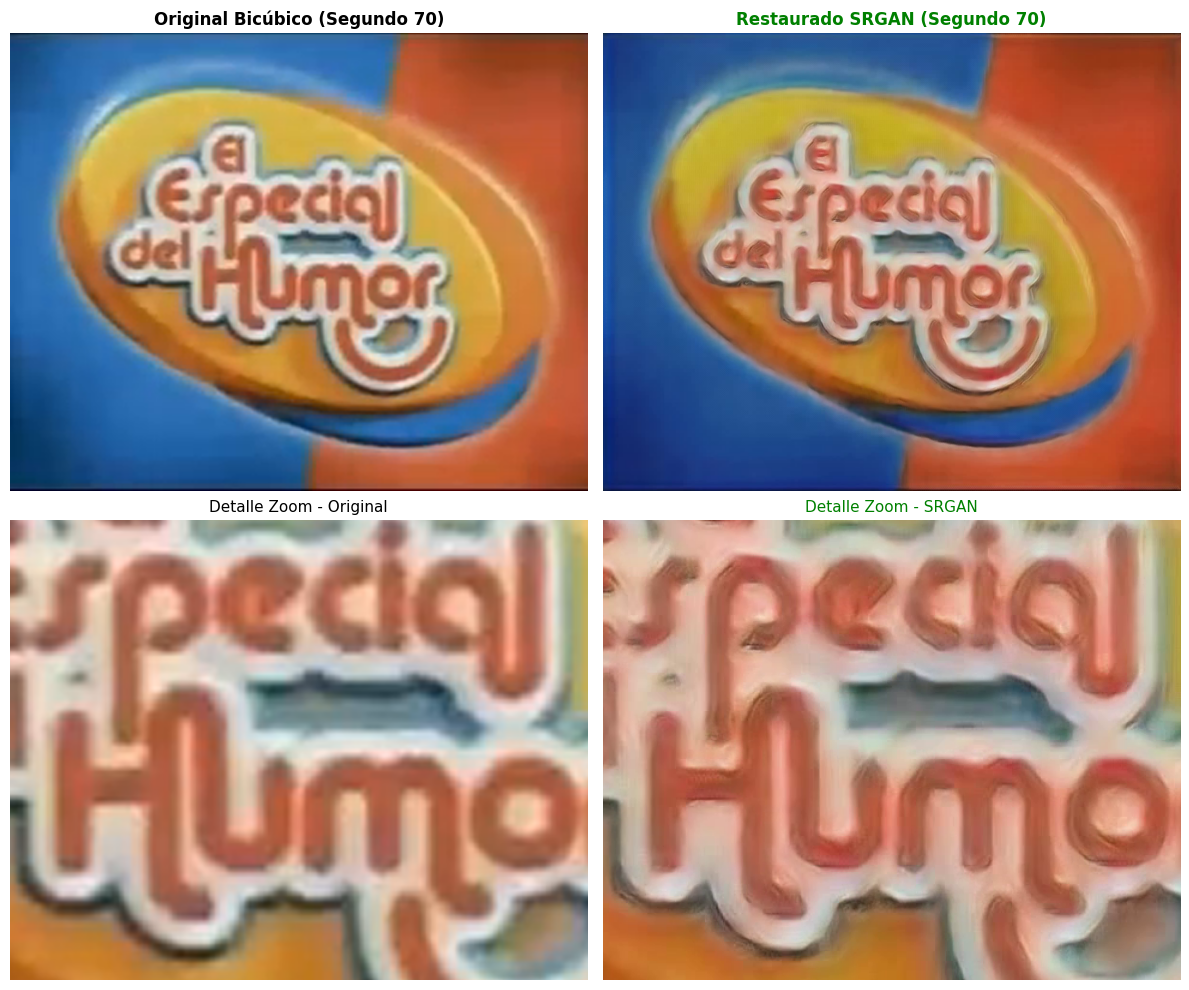

In [8]:
import cv2
import matplotlib.pyplot as plt

SEGUNDO_A_COMPARAR = 70   # Cambia este valor al segundo exacto que quieras analizar
VIDEO_ORIGINAL = "/content/video_original.mp4"
VIDEO_MEJORADO = "/content/resultado_final_srgan.mp4"

cap_orig = cv2.VideoCapture(VIDEO_ORIGINAL)
cap_sr = cv2.VideoCapture(VIDEO_MEJORADO)

fps = cap_orig.get(cv2.CAP_PROP_FPS)
frame_idx = int(SEGUNDO_A_COMPARAR * fps)

cap_orig.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
cap_sr.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)

ret1, frame_orig = cap_orig.read()
ret2, frame_sr = cap_sr.read()

cap_orig.release()
cap_sr.release()

if not ret1 or not ret2:
    raise ValueError("El segundo elegido supera la duración del video. Prueba con un número menor.")

orig_rgb = cv2.cvtColor(frame_orig, cv2.COLOR_BGR2RGB)
sr_rgb = cv2.cvtColor(frame_sr, cv2.COLOR_BGR2RGB)

h_sr, w_sr, _ = sr_rgb.shape
bicubic_rgb = cv2.resize(orig_rgb, (w_sr, h_sr), interpolation=cv2.INTER_CUBIC)

# Recorte (Zoom) en el centro
cy, cx = h_sr // 2, w_sr // 2
radio_y, radio_x = h_sr // 5, w_sr // 5

zoom_bicubic = bicubic_rgb[cy - radio_y : cy + radio_y, cx - radio_x : cx + radio_x]
zoom_sr = sr_rgb[cy - radio_y : cy + radio_y, cx - radio_x : cx + radio_x]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(bicubic_rgb)
axes[0, 0].set_title(f"Original Bicúbico (Segundo {SEGUNDO_A_COMPARAR})", fontsize=12, fontweight='bold')
axes[0, 0].axis("off")

axes[0, 1].imshow(sr_rgb)
axes[0, 1].set_title(f"Restaurado SRGAN (Segundo {SEGUNDO_A_COMPARAR})", fontsize=12, fontweight='bold', color='green')
axes[0, 1].axis("off")

axes[1, 0].imshow(zoom_bicubic)
axes[1, 0].set_title("Detalle Zoom - Original", fontsize=11)
axes[1, 0].axis("off")

axes[1, 1].imshow(zoom_sr)
axes[1, 1].set_title("Detalle Zoom - SRGAN", fontsize=11, color='green')
axes[1, 1].axis("off")

plt.tight_layout()
plt.savefig("/content/comparativa_fotograma_zoom.png", dpi=200)
plt.show()